# Evaluación final del sistema

Cristhian Pazmino Parra · Universidad Espíritu Santo

Comprueba decisiones congeladas, reservas, incertidumbre, estrés y despliegue con los resultados reales conservados.

Referente: anotaciones publicadas sin adjudicación local. Los datos permanecen fuera del repositorio.

In [1]:
from pathlib import Path
import json, sys
ROOT = Path.cwd()
assert (ROOT / "src").is_dir(), "Ejecutar desde la raíz del repositorio"
sys.path.insert(0, str(ROOT))
LOCAL = Path.home() / "AppData/Local/DentalAI"
DATA = LOCAL / "data/research_v2"
REPORTS = ROOT / "reports/completion"
def read(path):
    return json.loads(Path(path).read_text(encoding="utf-8"))
from IPython.display import display, Markdown, Image


In [2]:
evaluation = read(REPORTS / "evaluation.json")
metadata = read(ROOT / "models/research_v2/model.json")
assert metadata["weights_sha256"] == evaluation["decision"]["weights_sha256"]
assert metadata["threshold"] == evaluation["decision"]["threshold"]
display({s:{k:v[k] for k in ["images", "boxes", "map50", "map50_95", "false_positives_per_image"]} for s,v in evaluation["partitions"].items()})

{'train': {'images': 681,
  'boxes': 7128,
  'map50': 0.7006268342994415,
  'map50_95': 0.3445908299610833,
  'false_positives_per_image': 6.221732745961821},
 'val': {'images': 121,
  'boxes': 1254,
  'map50': 0.632788968120259,
  'map50_95': 0.2735197814512718,
  'false_positives_per_image': 6.636363636363637},
 'test': {'images': 94,
  'boxes': 1033,
  'map50': 0.7223359074290404,
  'map50_95': 0.3390386102736286,
  'false_positives_per_image': 7.0212765957446805},
 'external': {'images': 170,
  'boxes': 2046,
  'map50': 0.5707529487677162,
  'map50_95': 0.25987154564216824,
  'false_positives_per_image': 8.041176470588235}}

In [3]:
display(evaluation["partitions"]["test"]["by_class"])
display(evaluation["partitions"]["external"]["bootstrap95"])
display(read(REPORTS / "metric_parity.json"))

[{'class_id': 0,
  'class': 'caries',
  'support': 137,
  'tp': 53,
  'fp': 70,
  'fn': 84,
  'precision': 0.43089430894308944,
  'recall': 0.38686131386861317,
  'f1': 0.4076923076923077,
  'ap50': 0.3558397369121905,
  'ap50_95': 0.1352132965644431},
 {'class_id': 1,
  'class': 'lesion_periapical',
  'support': 80,
  'tp': 31,
  'fp': 21,
  'fn': 49,
  'precision': 0.5961538461538461,
  'recall': 0.3875,
  'f1': 0.46969696969696967,
  'ap50': 0.46660834665213813,
  'ap50_95': 0.17509851283191374},
 {'class_id': 2,
  'class': 'diente_impactado',
  'support': 56,
  'tp': 53,
  'fp': 19,
  'fn': 3,
  'precision': 0.7361111111111112,
  'recall': 0.9464285714285714,
  'f1': 0.828125,
  'ap50': 0.9209553803684238,
  'ap50_95': 0.45604981363227637},
 {'class_id': 3,
  'class': 'restauracion',
  'support': 385,
  'tp': 272,
  'fp': 163,
  'fn': 113,
  'precision': 0.6252873563218391,
  'recall': 0.7064935064935065,
  'f1': 0.6634146341463415,
  'ap50': 0.7302423176780583,
  'ap50_95': 0.3121

{'method': 'image_percentile',
 'patient_independence': 'unknown',
 'replicates': 1000,
 'seed': 42,
 'intervals': {'map50': {'low': 0.47307115060320387,
   'high': 0.6292343841886705,
   'valid_replicates': 991},
  'map50_95': {'low': 0.22415896705785893,
   'high': 0.3053246125895654,
   'valid_replicates': 991},
  'caries/recall': {'low': 0.25435244788283234,
   'high': 0.42426510615133367,
   'valid_replicates': 1000},
  'caries/ap50': {'low': 0.2202291895386701,
   'high': 0.3831914911026313,
   'valid_replicates': 1000},
  'lesion_periapical/recall': {'low': 0.18643082380764683,
   'high': 0.39398101898101895,
   'valid_replicates': 1000},
  'lesion_periapical/ap50': {'low': 0.13442181577645085,
   'high': 0.3494813891638656,
   'valid_replicates': 1000},
  'diente_impactado/recall': {'low': 0.761359396200814,
   'high': 0.9381601094045866,
   'valid_replicates': 1000},
  'diente_impactado/ap50': {'low': 0.6496593274098231,
   'high': 0.8896599528347735,
   'valid_replicates': 10

{'native_map50': 0.632788968120259,
 'cached_map50': 0.632788968120259,
 'native_map50_95': 0.27351978145127176,
 'cached_map50_95': 0.2735197814512718,
 'absolute_tolerance': 0.0001,
 'per_class_ap50_absolute_differences': {'caries': 0.0,
  'lesion_periapical': 0.0,
  'diente_impactado': 0.0,
  'restauracion': 0.0,
  'endodoncia': 0.0,
  'protesis_fija': 0.0,
  'implante': 0.0}}

In [4]:
stress = read(REPORTS / "stress.json")
assert len(stress) == 8
display([{ "scenario": r["scenario"], "delta_map50":r["delta_map50"]} for r in stress])
display(read(REPORTS / "application_verification.json"))
assert read(REPORTS / "export.json")["all_parity_checks_passed"]

[{'scenario': 'blur_sigma1.2', 'delta_map50': -0.028623224767094002},
 {'scenario': 'blur_sigma2.0', 'delta_map50': -0.12337242892567835},
 {'scenario': 'noise_sd5', 'delta_map50': -0.018222360302336482},
 {'scenario': 'noise_sd12', 'delta_map50': -0.11622479531536489},
 {'scenario': 'jpeg_quality40', 'delta_map50': -0.005849222603108717},
 {'scenario': 'brightness0.7', 'delta_map50': -0.03854256882267959},
 {'scenario': 'brightness1.3', 'delta_map50': -0.06717953912772501},
 {'scenario': 'downsample0.5', 'delta_map50': -0.015169131235531985}]

{'actual_final_weights': True,
 'model_sha256': '70b130153628b4564defae0d3542be4edef9eea147e2b2b4096b840761426d2e',
 'device': 'cpu',
 'tested_images': [{'sample_id': 'train_1066',
   'detections': 14,
   'request_ms': 252.0654999971157},
  {'sample_id': 'train_1071',
   'detections': 21,
   'request_ms': 101.57009999966249},
  {'sample_id': 'train_1073',
   'detections': 33,
   'request_ms': 98.88520000095014},
  {'sample_id': 'train_1081',
   'detections': 18,
   'request_ms': 122.03490000683814},
  {'sample_id': 'train_1104',
   'detections': 20,
   'request_ms': 133.19170000613667},
  {'sample_id': 'train_1109',
   'detections': 9,
   'request_ms': 107.40260001330171},
  {'sample_id': 'train_1112',
   'detections': 14,
   'request_ms': 103.99899999902118},
  {'sample_id': 'train_1127',
   'detections': 5,
   'request_ms': 106.80649999994785},
  {'sample_id': 'train_1134',
   'detections': 16,
   'request_ms': 95.46790001331829},
  {'sample_id': 'train_1143',
   'detections': 22,
  

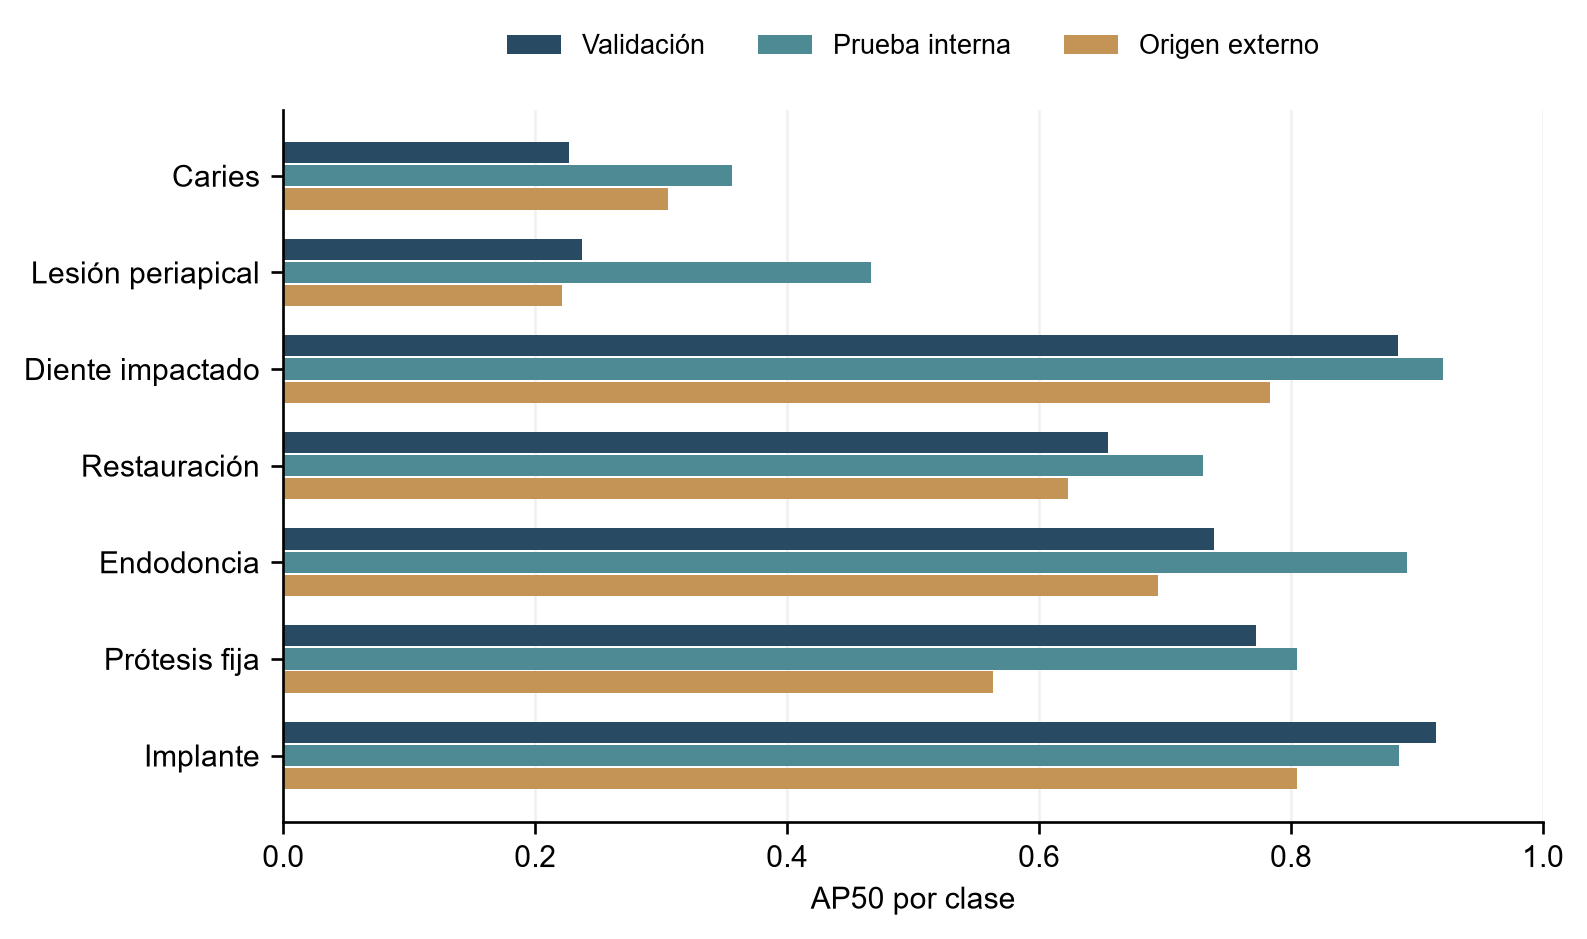

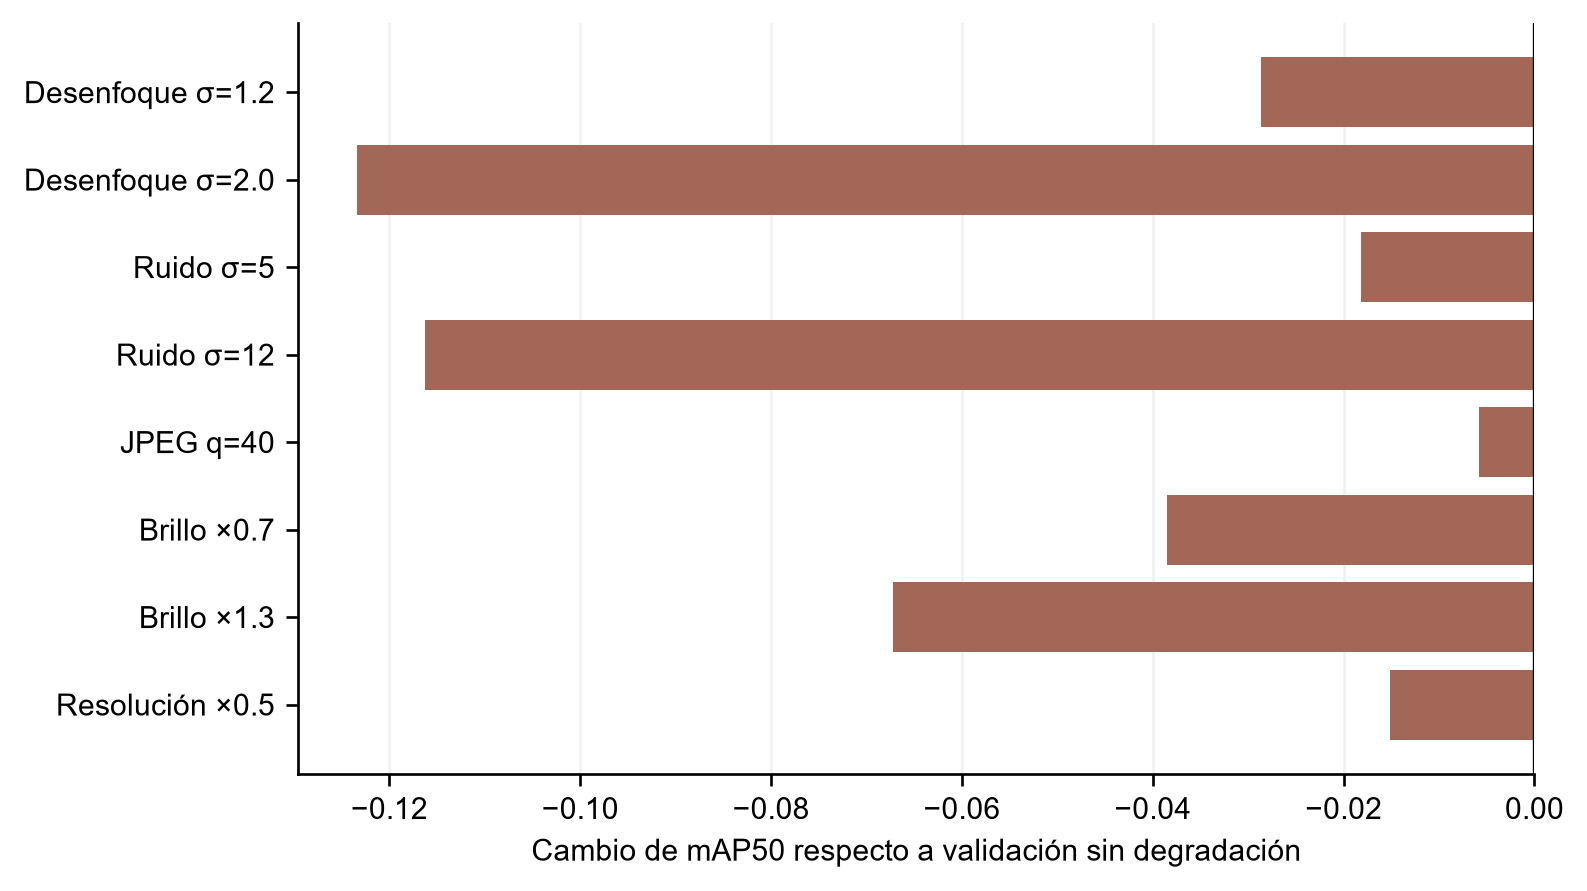

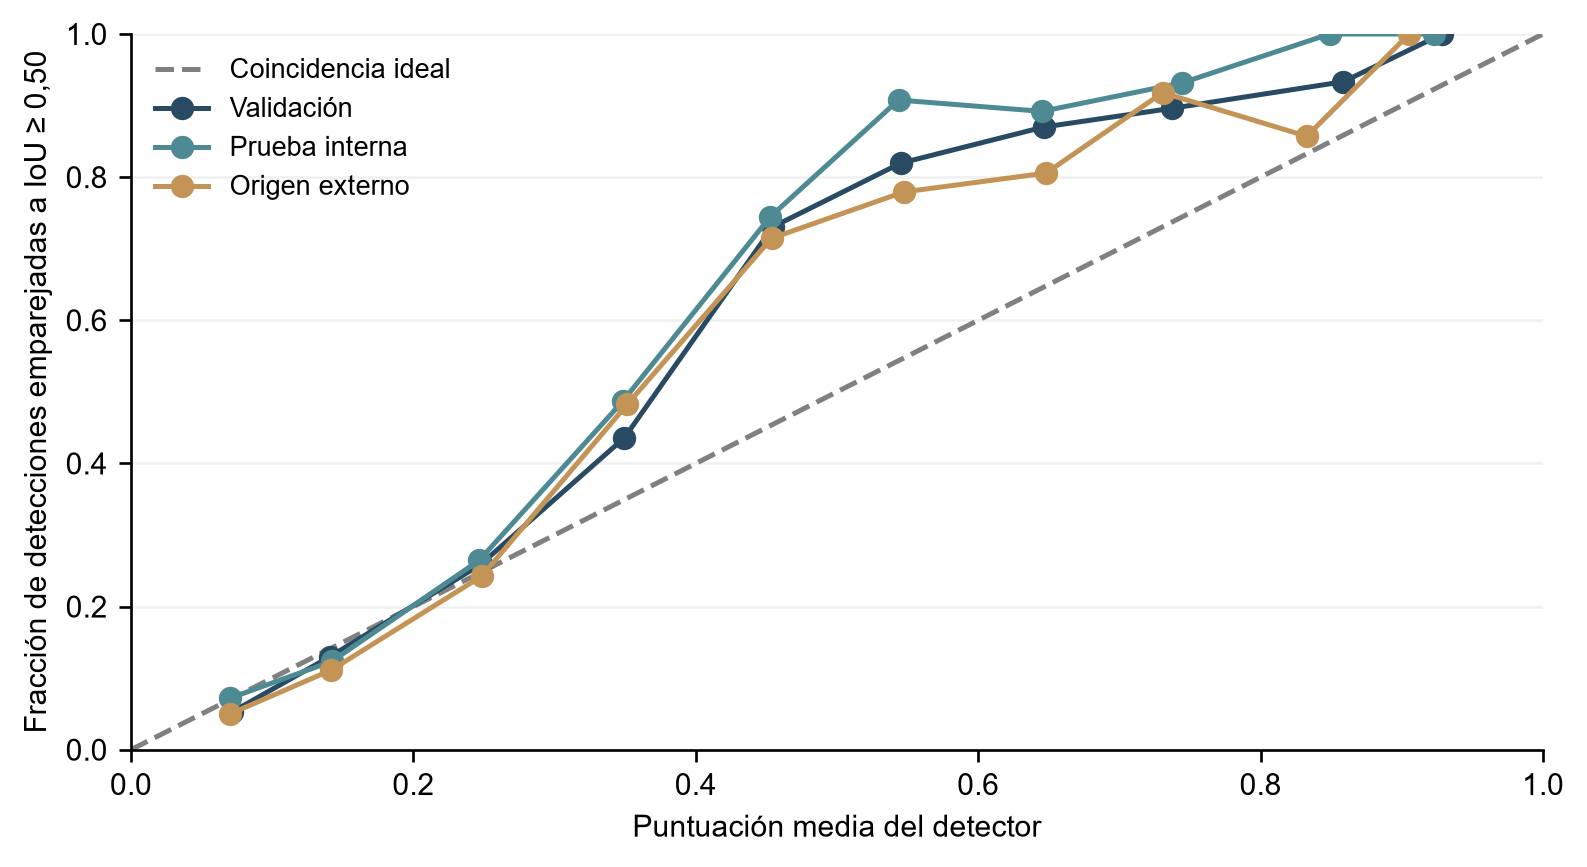

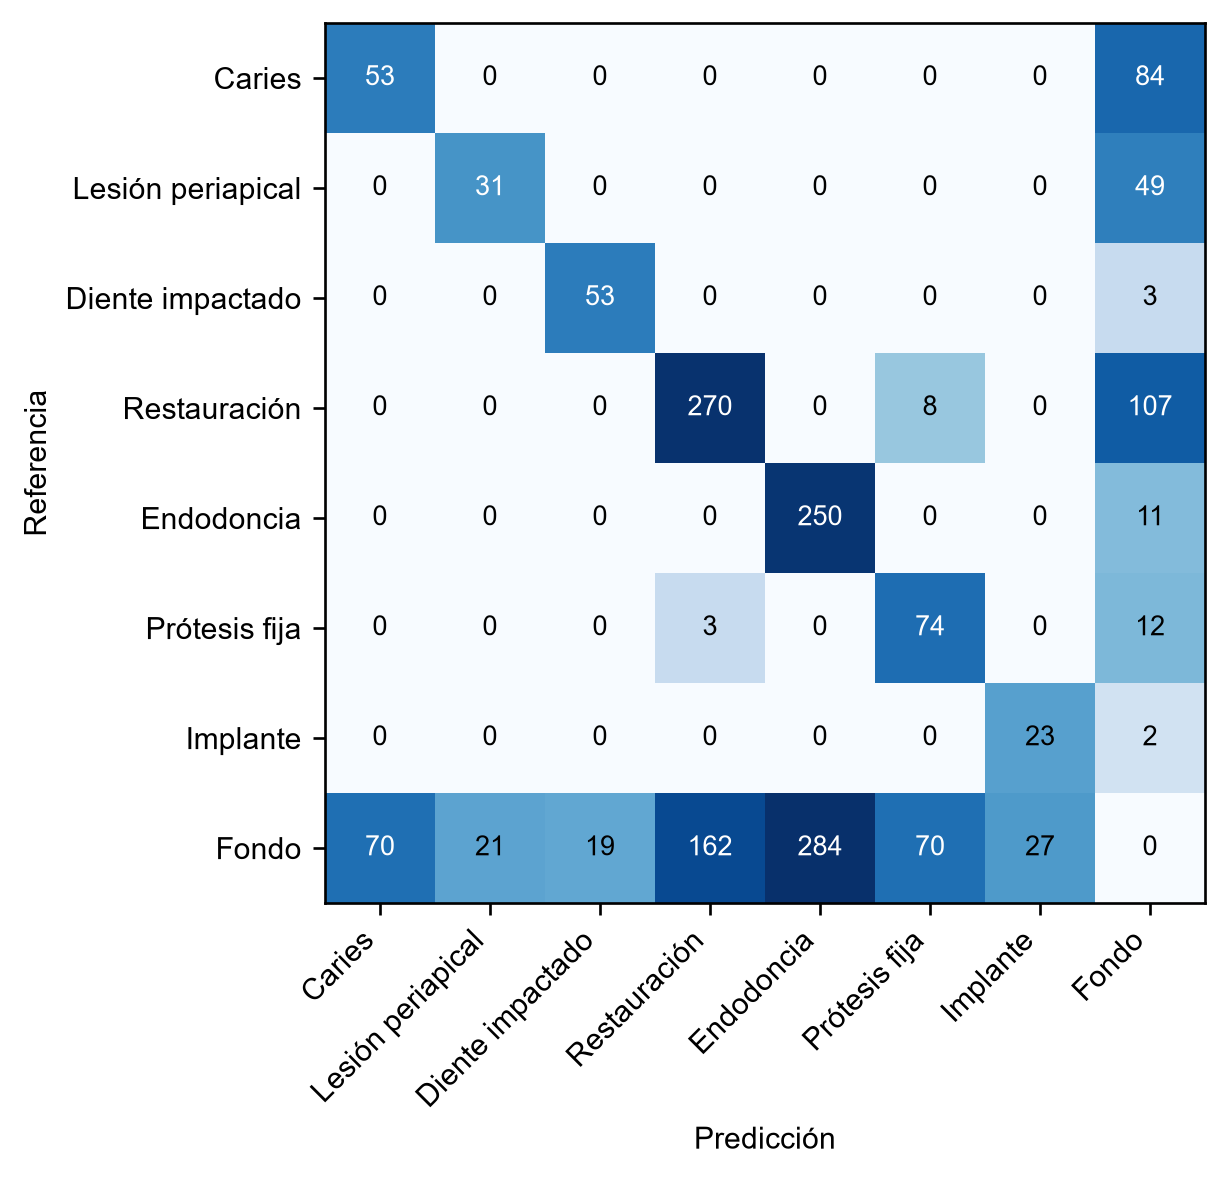

In [5]:
for name in ["v2_13_ap_holdouts.png", "v2_14_estres.png", "v2_15_calibracion.png", "v2_16_confusion.png"]:
    display(Image(filename=str(ROOT / "output/tesis/figures" / name)))

El bootstrap remuestrea imágenes, no pacientes conocidos. Las puntuaciones no son probabilidades de enfermedad. La ausencia de detecciones no descarta patología. Las instrucciones de ejecución están en README y los límites en la ficha de modelo.